# eRegulons, AUCell and RSS with `epione.scenic`

SCENIC+ (Bravo González-Blas *et al.*, Nat Methods 2023) links transcription factors to
their target **regions** and **genes** ("eRegulons"), scores them per cell with AUCell and
ranks them per cell type with the regulon specificity score (RSS). `epione.scenic`
re-implements this last part of the workflow:

| step | function | SCENIC+ equivalent |
|---|---|---|
| eRegulon inference (GSEA approach) | `epi.scenic.build_egrn` | `scenicplus.cli.commands.infer_grn` |
| TF–region–gene triplet ranking | `epi.scenic.triplet_rank`, `epi.scenic.tf_region_max_rank` | `scenicplus.triplet_score` |
| ranking cells once, AUCell | `epi.scenic.rank_cells`, `epi.scenic.score_eregulons` | `scenicplus.eregulon_enrichment.score_eRegulons` |
| regulon specificity | `epi.scenic.regulon_specificity_scores` | `scenicplus.RSS.regulon_specificity_scores` |

On the official SCENIC+ cerebellum tutorial data these functions reproduce SCENIC+ 1.0
**bit for bit**, including the random parts (GSEA permutations, random tie-breaking) and the row
order of the eRegulon table, and run 4–9x faster (numbers at the end of this notebook).

`build_egrn` needs three inputs: TF-to-gene links, region-to-gene links and cistromes (regions
carrying each TF's motif). In SCENIC+ they come from GRNBoost2, gradient-boosting
region-to-gene models and cisTarget. Those ports are separate `epione.scenic` modules; to keep
this tutorial self-contained it builds simple stand-ins with existing Epione tools: motif
scanning for cistromes and metacell correlations for both kinds of links. The eGRN, AUCell and
RSS steps are the same either way.

In [1]:
import os
import tarfile
import time
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import pooch
import matplotlib.pyplot as plt

import epione as epi

pooch.get_logger().setLevel("WARNING")

sc.settings.verbosity = 0
DATA = Path(os.environ.get("EPIONE_DATA_DIR", pooch.os_cache("epione"))) / "scenicplus_cerebellum"
DATA.mkdir(parents=True, exist_ok=True)

## Data: 10x multiome human cerebellum (3k cells)

The dataset of the official SCENIC+ and pycisTopic tutorials. The 10x filtered matrix holds both
gene expression and peak counts for the same cells; the cell-type labels come from the
pycisTopic repository.

In [2]:
tar = pooch.retrieve(
    "https://cf.10xgenomics.com/samples/cell-arc/2.0.0/human_brain_3k/"
    "human_brain_3k_filtered_feature_bc_matrix.tar.gz",
    known_hash="sha256:81a386c1f733e48d8fa6026e334e288333b2ad5586f9d4088bfe8b7528996fd4",
    path=DATA, progressbar=False)
cell_tsv = pooch.retrieve(
    "https://raw.githubusercontent.com/aertslab/pycisTopic/polars/data/cell_data_human_cerebellum.tsv",
    known_hash="sha256:e762f44f1a6523614c019419bf8971da536bba72ca5a0322d0e1b215f863a56c",
    path=DATA, progressbar=False)
mtx_dir = DATA / "filtered_feature_bc_matrix"
if not (mtx_dir / "matrix.mtx.gz").exists():
    with tarfile.open(tar) as t:
        t.extractall(DATA, filter="data")

both = sc.read_10x_mtx(mtx_dir, gex_only=False)
cell_data = pd.read_table(cell_tsv, index_col=0)
cell_data.index = cell_data.index.str.replace("-10x_multiome_brain", "", regex=False)
cells = both.obs_names.intersection(cell_data.index)
both = both[cells].copy()
rna = both[:, both.var["feature_types"] == "Gene Expression"].copy()
atac = both[:, both.var["feature_types"] == "Peaks"].copy()
rna.var_names_make_unique()
for a in (rna, atac):
    a.obs["cell_type"] = cell_data.loc[a.obs_names, "Seurat_cell_type"].astype("category")
print(rna, atac, sep="\n")
rna.obs["cell_type"].value_counts()

AnnData object with n_obs × n_vars = 2313 × 36601
    obs: 'cell_type'
    var: 'gene_ids', 'feature_types'
AnnData object with n_obs × n_vars = 2313 × 134030
    obs: 'cell_type'
    var: 'gene_ids', 'feature_types'


cell_type
MOL          813
BG           314
NFOL         305
OPC          183
GC           125
INH_VIP      111
MGL           74
COP           72
MG            68
INH_SST       66
GP            43
INH_SNCG      43
AST           37
PURK          28
ENDO          16
INH_PVALB     15
Name: count, dtype: int64

## Inputs for the eGRN

**Expression and embedding.** Log-normalised expression, 4,000 highly variable genes plus all
TFs with a JASPAR motif, and a PCA used to build metacells.

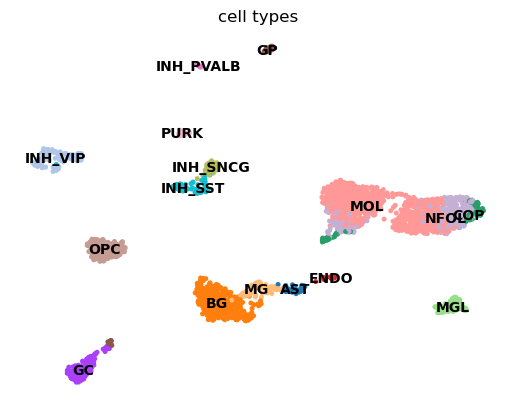

In [3]:
rna.layers["counts"] = rna.X.copy()
sc.pp.normalize_total(rna, target_sum=1e4)
sc.pp.log1p(rna)
sc.pp.highly_variable_genes(rna, n_top_genes=4000)
sc.pp.pca(rna, n_comps=30, mask_var="highly_variable")
sc.pp.neighbors(rna, n_pcs=30)
sc.tl.umap(rna)
atac.obsm["X_pca"] = rna.obsm["X_pca"]
sc.pl.umap(rna, color="cell_type", legend_loc="on data", frameon=False, title="cell types")

**Cistromes.** SCENIC+ defines a TF's cistrome as the regions of a cell-type-specific region set
(DARs or topics) that carry the TF's motif, *when that motif is enriched in the set* (cisTarget).
The same idea with Epione tools:

1. scan every peak with the JASPAR 2020 CORE vertebrate motifs (MOODS, p < 5e-5);
2. take the 3,000 most specific peaks of each cell type as region sets;
3. keep a motif's hits in a region set when the motif is enriched there (hypergeometric
   p < 1e-6, fold > 1.5); a TF's cistrome is the union over its motifs and region sets.

Only TFs expressed in at least one cell type (pseudobulk log-expression > 0.2) are kept.

In [4]:
%%time
import contextlib, io, warnings
from scipy import sparse
from scipy.stats import hypergeom

with warnings.catch_warnings(), contextlib.redirect_stderr(io.StringIO()):
    warnings.simplefilter("ignore")
    epi.tl.add_motif_matrix(atac, genome_fasta=str(epi.utils.genome.hg38.fasta),
                            motif_db="JASPAR2020", verbose=False)
motif_names = np.asarray(atac.uns["motif_names"])
M = sparse.csc_matrix(atac.varm["motif"]).astype(np.int64)

# cell-type-specific region sets
acc = sparse.csr_matrix(atac.X > 0).astype(np.float32)
ct = atac.obs["cell_type"]
n = acc.shape[0]
tot = np.asarray(acc.sum(0)).ravel()
region_sets = {}
for g in ct.cat.categories:
    sel = (ct == g).to_numpy()
    fg = np.asarray(acc[sel].sum(0)).ravel()
    frac, rest = fg / sel.sum(), (tot - fg) / (n - sel.sum())
    score = np.log2((frac + 0.01) / (rest + 0.01))
    score[frac < 0.05] = -np.inf
    region_sets[g] = np.argsort(-score)[:3000]

# motif enrichment per region set (cisTarget stand-in)
K = np.asarray(M.sum(0)).ravel()
cis_hits = {}  # motif -> set of peak indices
for g, idx in region_sets.items():
    k = np.asarray(M[idx].sum(0)).ravel()
    p = hypergeom.sf(k - 1, M.shape[0], K, len(idx))
    fold = (k / len(idx)) / np.maximum(K / M.shape[0], 1e-12)
    for j in np.flatnonzero((p < 1e-6) & (fold > 1.5)):
        hit = idx[M[idx, j].toarray().ravel() > 0]
        cis_hits.setdefault(j, set()).update(hit.tolist())

# motif -> TF (direct annotation), expressed TFs only
pb = pd.DataFrame(rna.X.toarray(), index=rna.obs_names, columns=rna.var_names).groupby(
    rna.obs["cell_type"].to_numpy()).mean()
expressed = set(pb.columns[(pb > 0.2).any(axis=0)])
tf_motifs, tf_peaks = {}, {}
for j, peaks in cis_hits.items():
    for tf in motif_names[j].split("_", 1)[-1].upper().split("::"):
        if tf in expressed:
            tf_motifs.setdefault(tf, []).append(motif_names[j])
            tf_peaks.setdefault(tf, set()).update(peaks)
tfs = sorted(tf_peaks)
cis = np.zeros((atac.n_vars, len(tfs)), dtype=bool)
for t, tf in enumerate(tfs):
    cis[list(tf_peaks[tf]), t] = True
cistromes = sc.AnnData(X=cis, obs=pd.DataFrame(index=atac.var_names),
                       var=pd.DataFrame({"motifs": [",".join(tf_motifs[t]) for t in tfs]}, index=tfs))
print(f"{len(tfs)} expressed TFs with an enriched motif; {cis.sum():,} TF-region pairs "
      f"in {cis.any(1).sum():,} regions")

65 expressed TFs with an enriched motif; 87,004 TF-region pairs in 21,704 regions
CPU times: user 2min 35s, sys: 2.29 s, total: 2min 38s
Wall time: 2min 41s


**Region-to-gene links.** Peak–gene Pearson correlations over 300 kNN metacells for all
peaks within 150 kb of a TSS (`epi.tl.peak_to_gene`). The absolute correlation stands in for
the gradient-boosting importance SCENIC+ uses, and the correlation sign plays the role of
SCENIC+'s Spearman ``rho``.

In [5]:
%%time
genes = epi.utils.get_gene_annotation(epi.utils.genome.hg38)
p2g = epi.tl.peak_to_gene(atac, rna=rna, gene_annotation=genes, use_rep="X_pca", n_metacells=300,
                          k_neighbors=50, max_distance=150_000, seed=0, inplace=False, verbose=False)
p2g = p2g.dropna(subset=["correlation"])
r2g = pd.DataFrame({"target": p2g["gene"].to_numpy(), "region": p2g["peak"].to_numpy(),
                    "importance": p2g["correlation"].abs().to_numpy(),
                    "rho": p2g["correlation"].to_numpy()})
r2g["importance_x_rho"] = r2g["importance"] * r2g["rho"]
r2g["importance_x_abs_rho"] = r2g["importance"] * r2g["rho"].abs()
print(f"{len(r2g):,} region-to-gene links, {r2g.target.nunique():,} genes, {r2g.region.nunique():,} regions")

391,304 region-to-gene links, 18,648 genes, 105,195 regions
CPU times: user 5.81 s, sys: 1.05 s, total: 6.86 s
Wall time: 6.64 s


**TF-to-gene links.** Pearson correlation between each TF and each gene over the same kind of
metacells; again the absolute correlation is the importance used to rank a TF's targets.

In [6]:
%%time
rng = np.random.default_rng(0)
anchors = rng.choice(rna.n_obs, 300, replace=False)
dist = ((rna.obsm["X_pca"][anchors, None, :] - rna.obsm["X_pca"][None, :, :]) ** 2).sum(-1)
knn = np.argsort(dist, axis=1)[:, :50]
keep_genes = rna.var_names[rna.var["highly_variable"] | rna.var_names.isin(tfs)]
X = rna[:, keep_genes].X.toarray()
meta = np.stack([X[k].mean(0) for k in knn])
meta = (meta - meta.mean(0)) / (meta.std(0) + 1e-12)
cor = meta.T @ meta / meta.shape[0]
gi = pd.Index(keep_genes)
rows = []
for tf in tfs:
    c = cor[gi.get_loc(tf)]
    rows.append(pd.DataFrame({"TF": tf, "target": keep_genes, "importance": np.abs(c), "rho": c}))
tf2g = pd.concat(rows, ignore_index=True)
tf2g = tf2g[tf2g["TF"] != tf2g["target"]]
tf2g["regulation"] = np.sign(tf2g["rho"]).astype(int)
tf2g = tf2g[["TF", "target", "importance", "regulation", "rho"]].reset_index(drop=True)
print(f"{len(tf2g):,} TF-to-gene links for {tf2g.TF.nunique()} TFs")

261,950 TF-to-gene links for 65 TFs
CPU times: user 436 ms, sys: 79.1 ms, total: 515 ms
Wall time: 311 ms


## eRegulons

`build_egrn` binarises the region-to-gene links per gene in seven ways (quantiles 0.85/0.90/0.95,
top 5/10/15 regions, BASC) and per correlation sign, intersects them with each cistrome, tests
each candidate's genes with GSEA against the TF's ranked targets (1,000 permutations), keeps the
leading edge and merges the candidates into eRegulons named `TF_direct_<tf2g sign>/<r2g sign>`.

The triplet ranking needs motif ranks from a cisTarget database; without one the
`triplet_rank` column is left out (pass `ranking_db=` or `tf_region_rank=` to add it).

In [7]:
%%time
eregulons = epi.scenic.build_egrn(tf2g, r2g, cistromes, is_extended=False, min_target_genes=10)
print(f"{eregulons.eRegulon_name.nunique()} eRegulons, {len(eregulons):,} TF-region-gene links")
eregulons.head()

108 eRegulons, 10,256 TF-region-gene links
CPU times: user 18.4 s, sys: 930 ms, total: 19.3 s
Wall time: 11.9 s


,Region,Gene,importance_R2G,rho_R2G,importance_x_rho,importance_x_abs_rho,TF,is_extended,eRegulon_name,Gene_signature_name,Region_signature_name,importance_TF2G,regulation,rho_TF2G
0,chr8:55149062-55149884,XKR4,0.571140,0.571140,0.326201,0.326201,ASCL1,False,ASCL1_direct_+/+,ASCL1_direct_+/+_(37g),ASCL1_direct_+/+_(39r),0.389395,1,0.389395
1,chr20:44861349-44862164,PABPC1L,0.097674,0.097674,0.009540,0.009540,ASCL1,False,ASCL1_direct_+/+,ASCL1_direct_+/+_(37g),ASCL1_direct_+/+_(39r),0.416752,1,0.416752
2,chr7:49839826-49840622,VWC2,0.755074,0.755074,0.570137,0.570137,ASCL1,False,ASCL1_direct_+/+,ASCL1_direct_+/+_(37g),ASCL1_direct_+/+_(39r),0.369234,1,0.369234
3,chr7:55140077-55140923,EGFR,0.744941,0.744941,0.554937,0.554937,ASCL1,False,ASCL1_direct_+/+,ASCL1_direct_+/+_(37g),ASCL1_direct_+/+_(39r),0.579727,1,0.579727
4,chr20:19323539-19324481,SLC24A3,0.558551,0.558551,0.311979,0.311979,ASCL1,False,ASCL1_direct_+/+,ASCL1_direct_+/+_(37g),ASCL1_direct_+/+_(39r),0.685549,1,0.685549


In [8]:
summary = (eregulons.groupby("eRegulon_name")
           .agg(n_genes=("Gene", "nunique"), n_regions=("Region", "nunique"))
           .sort_values("n_genes", ascending=False))
summary.head(15)

,n_genes,n_regions
eRegulon_name,,
SPI1_direct_+/+,465,764
IKZF1_direct_+/+,390,552
ELF1_direct_+/+,277,388
ETV6_direct_+/+,273,295
RUNX1_direct_+/+,228,270
ETV5_direct_+/+,168,160
FOSL2_direct_+/+,164,218
ZBTB7A_direct_-/+,157,173
SMAD3_direct_+/+,150,186


## AUCell

Each cell's genes (raw counts) and peaks are ranked once, with random tie-breaking seeded as in
SCENIC+, and every signature is scored from the same ranking; scoring further signature sets
(for example extended eRegulons) does not re-rank.

In [9]:
%%time
gex_rank = epi.scenic.rank_cells(rna.layers["counts"].astype(np.float32), rna.obs_names, rna.var_names)
acc_rank = epi.scenic.rank_cells(atac.X.astype(np.int32), atac.obs_names, atac.var_names)
auc = epi.scenic.score_eregulons(eregulons, gex_rank, acc_rank)
auc["Gene_based"].iloc[:5, :5]

CPU times: user 24.3 s, sys: 550 ms, total: 24.8 s
Wall time: 15.2 s


,ASCL1_direct_+/+_(37g),ASCL1_direct_-/+_(29g),ATF2_direct_-/-_(36g),BACH1_direct_+/-_(61g),BACH1_direct_-/+_(41g)
Cell,,,,,
AAACAGCCATTATGCG-1,0.003559,0.067854,0.001078,0.017603,0.001679
AAACCAACATAGACCC-1,0.000000,0.045223,0.011825,0.006978,0.030055
AAACCGAAGATGCCTG-1,0.227972,0.288920,0.000000,0.003977,0.040517
AAACCGAAGTTAGCTA-1,0.031280,0.000000,0.000000,0.000000,0.008530
AAACCGCGTTAGCCAA-1,0.025299,0.038138,0.298285,0.234964,0.000000


## Regulon specificity per cell type

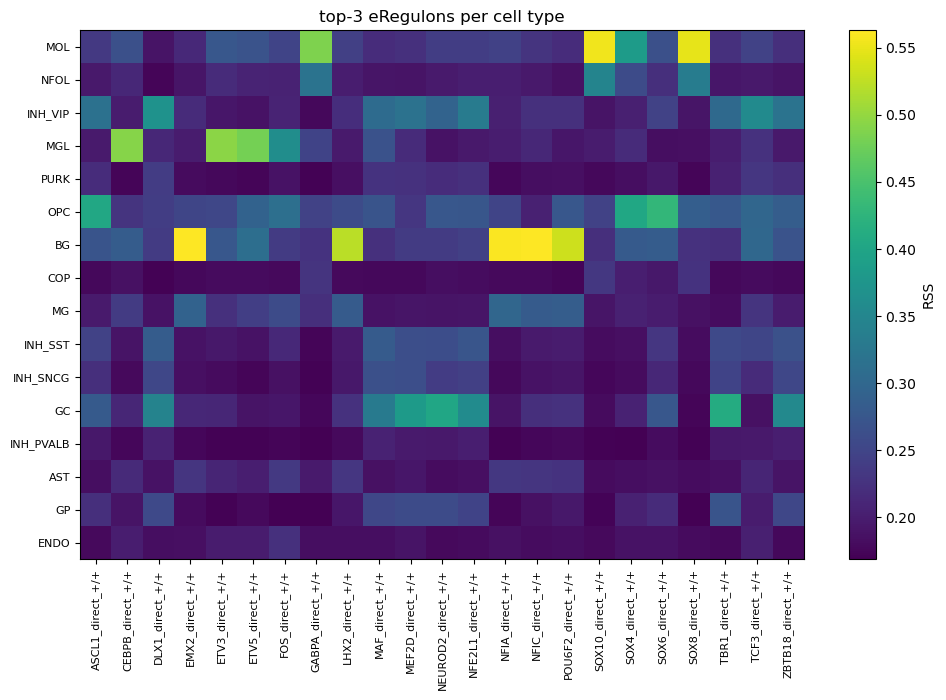

In [10]:
rss = epi.scenic.regulon_specificity_scores(auc["Gene_based"], rna.obs["cell_type"])
# show activator eRegulons (TF2G +, R2G +) with at least 10 target genes, as the SCENIC+ tutorial does
act = [c for c in rss.columns if "_+/+_" in c and int(c.rsplit("(", 1)[1][:-2]) >= 10]
rss = rss[act]
top = sorted({r for ct in rss.index for r in rss.loc[ct].nlargest(3).index})
fig, ax = plt.subplots(figsize=(0.35 * len(top) + 2, 0.35 * len(rss) + 1.5))
im = ax.imshow(rss[top].to_numpy(), aspect="auto", cmap="viridis")
ax.set_xticks(range(len(top)), [t.split("_(")[0] for t in top], rotation=90, fontsize=8)
ax.set_yticks(range(len(rss)), rss.index, fontsize=8)
fig.colorbar(im, ax=ax, label="RSS")
ax.set_title("top-3 eRegulons per cell type")
plt.tight_layout()

In [11]:
best = rss.idxmax(axis=1).rename("most specific eRegulon").to_frame()
best["RSS"] = rss.max(axis=1).round(3)
best

,most specific eRegulon,RSS
MOL,SOX10_direct_+/+_(46g),0.554
NFOL,SOX10_direct_+/+_(46g),0.347
INH_VIP,DLX1_direct_+/+_(32g),0.370
MGL,ETV3_direct_+/+_(92g),0.494
PURK,DLX1_direct_+/+_(32g),0.239
OPC,SOX6_direct_+/+_(18g),0.430
BG,EMX2_direct_+/+_(74g),0.563
COP,SOX10_direct_+/+_(46g),0.233
MG,NFIA_direct_+/+_(70g),0.299
INH_SST,DLX1_direct_+/+_(32g),0.283


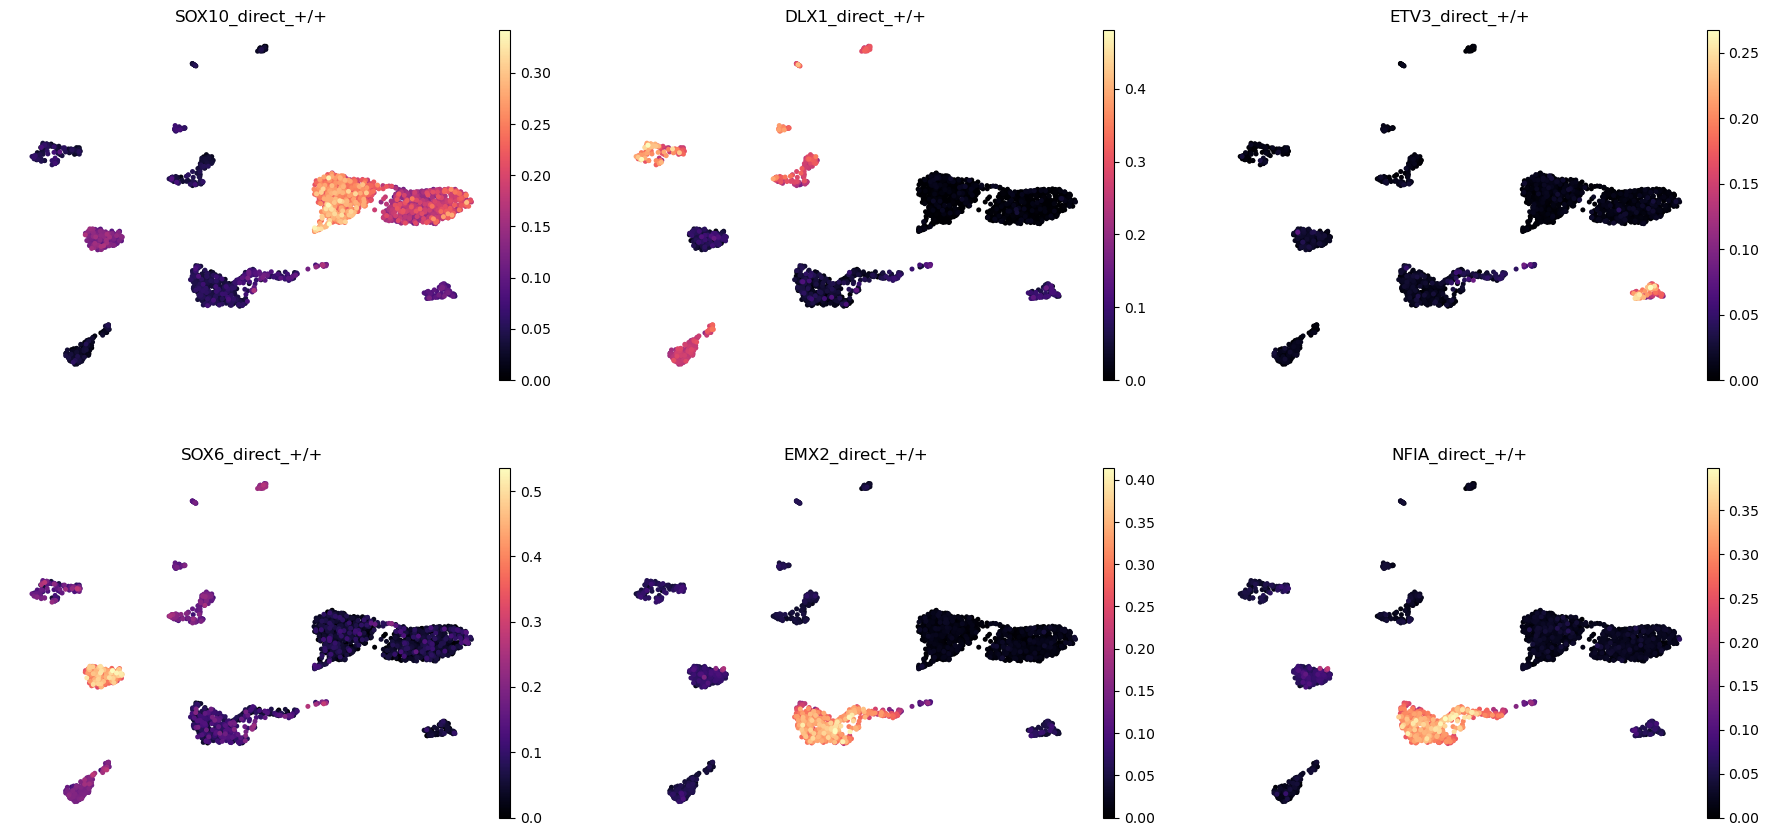

In [12]:
show = list(dict.fromkeys(best["most specific eRegulon"]))[:6]
for s in show:
    rna.obs[s.split("_(")[0]] = auc["Gene_based"].loc[rna.obs_names, s].to_numpy()
sc.pl.umap(rna, color=[s.split("_(")[0] for s in show], ncols=3, frameon=False, cmap="magma")

## Parity with SCENIC+ 1.0

The port was checked against SCENIC+ 1.0a2 (pycisTopic 2.0a0, ctxcore 0.2.0, pyscenic 0.12.1,
gseapy 0.10.8, numpy 1.26.4) run on this dataset through its full pipeline (topics → cisTarget/DEM →
GRNBoost2 → GBM region-to-gene → eGRN → AUCell → RSS; each reference stage was run twice and is
byte-identical). Thresholds were registered before the comparison
(`tests/parity/scenic_egrn/MANIFEST.md`); the comparison ran with numpy 2.4, so the identical
results do not depend on the numpy version.

| # | output | Epione vs SCENIC+ | gate |
|---|---|---|---|
| 1 | per-gene R2G thresholds (3 quantiles, 3 top-n, BASC; both signs) | max abs err 0 | `== 0` ✅ |
| 2 | GSEA per candidate eModule (12,224 direct + 5,674 extended calls): NES, p, leading edge | identical | `== 0` ✅ |
| 3 | eRegulon table, as a set of rows (direct 28,242 rows / 125 eRegulons; extended 13,700 / 74) | identical | `== 0` ✅ |
| 4 | eRegulon table row order (`PYTHONHASHSEED=0`) | identical | `== 0` ✅ |
| 5 | `triplet_rank` | identical | `== 0` ✅ |
| 6 | AUCell gene-based AUC (2,313 cells), direct and extended | max abs err 0 | `<= 1e-8` ✅ |
| 7 | AUCell region-based AUC, direct and extended | max abs err 0 | `<= 1e-8` ✅ |
| 8 | RSS (16 cell types × 199 eRegulons) | max abs err 0 | `<= 1e-8` ✅ |

Where SCENIC+ itself is not reproducible across library versions, the port follows the
reference environment explicitly. SCENIC+ breaks ties by shuffling and then calling
numpy's unstable `argsort`, whose tie order changed between numpy 1.26 and 2.x on AVX-512 CPUs;
`epione.scenic` contains a deterministic emulation of numpy 1.26's AVX-512 argsort. numpy 1.x
summed in 8,192-element blocks; the GSEA normalisation does the same explicitly. The relative
entropy in RSS calls the C library `log` as SciPy 1.12 did. Without these steps, numpy 2.x changes
36–61% of the AUC values (by up to 0.024) and the last bit of some RSS values.

Wall time on the same data (SCENIC+ with 4 workers; Epione with 8 threads, numba JIT already
cached; the first call compiles for about a minute):

| stage | SCENIC+ | Epione |
|---|---|---|
| eGRN direct, incl. reading the cisTarget ranking DB for the triplet ranking | 768 s | 136 s (78 s + 58 s DB) |
| eGRN extended, same | 374 s | 59 s (33 s + 26 s DB) |
| AUCell direct + extended | 159 s + 159 s | 71 s ranking (shared) + 1.6 s + 1.3 s |
| RSS | 0.9 s | 0.7 s |